# Classical subtropical Stommel gyre

This example computes the planetary-geostrophic analogue of a classical Stommel subtropical gyre. A flat rectangular basin on a beta plane is forced by a zonal wind stress with negative curl throughout the interior. Buoyancy forcing is zero, so the circulation is barotropic and the solution isolates the Sverdrup interior and frictional western boundary current.

With the convention $(U,V)=(-\partial_y\Psi,\partial_x\Psi)$, the inviscid interior satisfies

$$\beta V = \mathrm{Ek}\,\hat{\boldsymbol z}\mathbin{\boldsymbol\cdot}(\boldsymbol\nabla\mathbin{\boldsymbol\times}\boldsymbol\tau),$$

while the analytical PG bottom stress closes the circulation near the basin boundary.

In [1]:
using Pkg
Pkg.activate(joinpath(@__DIR__, "..", "PlanetaryGeostrophy"))
using PlanetaryGeostrophy
using Plots

  Activating project at `~/Library/CloudStorage/OneDrive-JohnsHopkins/Documents/Articles/Manuscripts/In prep/Haine_etal/WorkingResearch/PlanetaryGeostrophyAnalyticalModel/PlanetaryGeostrophy`


## Basin and forcing

The wind changes from westward at the southern boundary to eastward at the northern boundary. Its curl is negative between the boundaries, producing a single anticyclonic subtropical gyre.

In [2]:
Lx, Ly = 2.0, 1.0
H0 = 1.0
f0, beta = 1.0, 0.60
Ek, Γ = 0.0025, 0.20
tau0 = 5e-4

eta(y) = (y + Ly / 2) / Ly
tau_x(x, y) = -tau0 * cos(pi * eta(y))
tau_y(x, y) = 0.0
wind_curl(x, y) = -tau0 * pi / Ly * sin(pi * eta(y))

problem = PGProblem(
    parameters=PGParameters(Ek, Γ; viscosity=1.0, diffusivity=1.0),
    depth=(x, y) -> H0,
    depth_x=(x, y) -> 0.0,
    depth_y=(x, y) -> 0.0,
    coriolis=(x, y) -> f0 + beta * y,
    coriolis_x=(x, y) -> 0.0,
    coriolis_y=(x, y) -> beta,
    wind_stress=(x, y) -> tau_x(x, y) + im * tau_y(x, y),
    wind_stress_curl=wind_curl,
    restoring_buoyancy=(x, y, z) -> 0.0,
    surface_buoyancy=(x, y) -> 0.0,
    boundary=rectangle_boundary(Lx, Ly),
)

PGProblem{PGParameters{Float64}, var"#31#32", var"#37#38", var"#39#40", var"#41#42", var"#43#44", typeof(wind_curl), var"#45#46", var"#47#48", var"#33#34", var"#35#36", Vector{Tuple{Float64, Float64}}, PlanetaryGeostrophy.var"#163#164"{Vector{Tuple{Float64, Float64}}}}(PGParameters{Float64}(0.0025, 0.2, 1.0, 1.0), var"#31#32"(), var"#37#38"(), var"#39#40"(), var"#41#42"(), var"#43#44"(), Main.wind_curl, var"#45#46"(), var"#47#48"(), var"#33#34"(), var"#35#36"(), [(-1.0, -0.5), (1.0, -0.5), (1.0, 0.5), (-1.0, 0.5)], PlanetaryGeostrophy.var"#163#164"{Vector{Tuple{Float64, Float64}}}([(-1.0, -0.5), (1.0, -0.5), (1.0, 0.5), (-1.0, 0.5)]), 1.0e-5)

## Surface-pressure and transport solution

In [3]:
solution = solve_pg(
    problem;
    mesh_file=joinpath(@__DIR__, "stommel_pg_pressure.msh"),
    mesh_resolution=0.03,
    pressure_order=2,
    overwrite_mesh=true,
)
display(performance_summary(solution))

┌ Info: PG solve started
│   Ek = 0.0025
│   Γ = 0.2
│   viscosity = 1.0
│   diffusivity = 1.0
│   pressure_order = 2
│   mesh_resolution = 0.03
│   mesh_file = /Users/twnh/Library/CloudStorage/OneDrive-JohnsHopkins/Documents/Articles/Manuscripts/In prep/Haine_etal/WorkingResearch/PlanetaryGeostrophyAnalyticalModel/AnalyticalModel/stommel_pg_pressure.msh
└ @ PlanetaryGeostrophy /Users/twnh/Library/CloudStorage/OneDrive-JohnsHopkins/Documents/Articles/Manuscripts/In prep/Haine_etal/WorkingResearch/PlanetaryGeostrophyAnalyticalModel/PlanetaryGeostrophy/src/PlanetaryGeostrophy.jl:269
┌ Info: Starting generating surface mesh
└ @ PlanetaryGeostrophy /Users/twnh/Library/CloudStorage/OneDrive-JohnsHopkins/Documents/Articles/Manuscripts/In prep/Haine_etal/WorkingResearch/PlanetaryGeostrophyAnalyticalModel/PlanetaryGeostrophy/src/PlanetaryGeostrophy.jl:18


Info    : Meshing 1D...
Info    : [  0%] Meshing curve 1 (Line)
Info    : [ 30%] Meshing curve 2 (Line)
Info    : [ 60%] Meshing curve 3 (Line)
Info    : [ 80%] Meshing curve 4 (Line)
Info    : Done meshing 1D (Wall 0.000174917s, CPU 0.000159s)
Info    : Meshing 2D...
Info    : Meshing surface 1 (Plane, Frontal-Delaunay)
Info    : Done meshing 2D (Wall 0.030184s, CPU 0.029707s)
Info    : 2744 nodes 5490 elements
Info    : Writing '/Users/twnh/Library/CloudStorage/OneDrive-JohnsHopkins/Documents/Articles/Manuscripts/In prep/Haine_etal/WorkingResearch/PlanetaryGeostrophyAnalyticalModel/AnalyticalModel/stommel_pg_pressure.msh'...
Info    : Done writing '/Users/twnh/Library/CloudStorage/OneDrive-JohnsHopkins/Documents/Articles/Manuscripts/In prep/Haine_etal/WorkingResearch/PlanetaryGeostrophyAnalyticalModel/AnalyticalModel/stommel_pg_pressure.msh'


┌ Info: Completed generating surface mesh
│   seconds = 0.087
│   allocated_mib = 3.48
│   gc_seconds = 0.0
└ @ PlanetaryGeostrophy /Users/twnh/Library/CloudStorage/OneDrive-JohnsHopkins/Documents/Articles/Manuscripts/In prep/Haine_etal/WorkingResearch/PlanetaryGeostrophyAnalyticalModel/PlanetaryGeostrophy/src/PlanetaryGeostrophy.jl:21
┌ Info: Starting loading analytical Green-function kernels
└ @ PlanetaryGeostrophy /Users/twnh/Library/CloudStorage/OneDrive-JohnsHopkins/Documents/Articles/Manuscripts/In prep/Haine_etal/WorkingResearch/PlanetaryGeostrophyAnalyticalModel/PlanetaryGeostrophy/src/PlanetaryGeostrophy.jl:18


Info    : Reading '/Users/twnh/Library/CloudStorage/OneDrive-JohnsHopkins/Documents/Articles/Manuscripts/In prep/Haine_etal/WorkingResearch/PlanetaryGeostrophyAnalyticalModel/AnalyticalModel/stommel_pg_pressure.msh'...
Info    : 9 entities
Info    : 2744 nodes
Info    : 5486 elements
Info    : Done reading '/Users/twnh/Library/CloudStorage/OneDrive-JohnsHopkins/Documents/Articles/Manuscripts/In prep/Haine_etal/WorkingResearch/PlanetaryGeostrophyAnalyticalModel/AnalyticalModel/stommel_pg_pressure.msh'


┌ Info: Completed loading analytical Green-function kernels
│   seconds = 0.0
│   allocated_mib = 0.0
│   gc_seconds = 0.0
└ @ PlanetaryGeostrophy /Users/twnh/Library/CloudStorage/OneDrive-JohnsHopkins/Documents/Articles/Manuscripts/In prep/Haine_etal/WorkingResearch/PlanetaryGeostrophyAnalyticalModel/PlanetaryGeostrophy/src/PlanetaryGeostrophy.jl:21
┌ Info: Surface-pressure solve started
│   mesh_file = /Users/twnh/Library/CloudStorage/OneDrive-JohnsHopkins/Documents/Articles/Manuscripts/In prep/Haine_etal/WorkingResearch/PlanetaryGeostrophyAnalyticalModel/AnalyticalModel/stommel_pg_pressure.msh
│   finite_element_order = 2
│   method = fast
│   coastal_condition = no_normal_flow
│   threads = 18
└ @ PlanetaryGeostrophy /Users/twnh/Library/CloudStorage/OneDrive-JohnsHopkins/Documents/Articles/Manuscripts/In prep/Haine_etal/WorkingResearch/PlanetaryGeostrophyAnalyticalModel/AnalyticalModel/SurfacePressureTools.jl:252
┌ Info: Starting loading Gridap surface mesh
└ @ PlanetaryGeostrophy 

(mesh = (seconds = 0.086872167, allocated_mib = 3.4816436767578125, gc_seconds = 0.0), kernels = (seconds = 0.0, allocated_mib = 0.0, gc_seconds = 0.0), surface_pressure = (mesh_load = (seconds = 2.815597958, allocated_mib = 613.7574615478516, gc_seconds = 0.032063541), finite_element_setup = (seconds = 3.929921167, allocated_mib = 1779.3285369873047, gc_seconds = 0.096374916), forcing_evaluation = (seconds = 2.641557583, allocated_mib = 4192.389755249023, gc_seconds = 0.169960626), operator_assembly = (seconds = 7.54630025, allocated_mib = 1518.2149963378906, gc_seconds = 0.042964709), linear_solve = (seconds = 0.225307292, allocated_mib = 53.710235595703125, gc_seconds = 0.01478125), total_seconds = 19.725892066955566, forcing_points = 31704), total_seconds = 19.87955904006958)

In [4]:
# Stay just inside the finite-element boundary for point evaluation.
x = range(-0.99Lx / 2, 0.99Lx / 2; length=101)
y = range(-0.99Ly / 2, 0.99Ly / 2; length=51)
diagnostics = compute_diagnostics(solution, x, y)
display(performance_summary(diagnostics))

┌ Info: PG diagnostic calculation started
│   Nx = 101
│   Ny = 51
│   horizontal_points = 5151
└ @ PlanetaryGeostrophy /Users/twnh/Library/CloudStorage/OneDrive-JohnsHopkins/Documents/Articles/Manuscripts/In prep/Haine_etal/WorkingResearch/PlanetaryGeostrophyAnalyticalModel/PlanetaryGeostrophy/src/PlanetaryGeostrophy.jl:2509
┌ Info: Transport streamfunction solve started
│   finite_element_order = 2
└ @ PlanetaryGeostrophy /Users/twnh/Library/CloudStorage/OneDrive-JohnsHopkins/Documents/Articles/Manuscripts/In prep/Haine_etal/WorkingResearch/PlanetaryGeostrophyAnalyticalModel/AnalyticalModel/SurfacePressureTools.jl:571
┌ Info: Starting constructing streamfunction finite-element spaces
└ @ PlanetaryGeostrophy /Users/twnh/Library/CloudStorage/OneDrive-JohnsHopkins/Documents/Articles/Manuscripts/In prep/Haine_etal/WorkingResearch/PlanetaryGeostrophyAnalyticalModel/AnalyticalModel/SurfacePressureTools.jl:12
┌ Info: Completed constructing streamfunction finite-element spaces
│   seconds = 

(streamfunction = (finite_element_setup = (seconds = 1.001364458, allocated_mib = 487.44847106933594, gc_seconds = 0.010232333), current_projection = (seconds = 5.079648125, allocated_mib = 1752.103744506836, gc_seconds = 0.147323455), operator_assembly = (seconds = 3.02652575, allocated_mib = 419.0726623535156, gc_seconds = 0.008571625), linear_solve = (seconds = 0.071717542, allocated_mib = 22.512588500976562, gc_seconds = 0.02297975), total_seconds = 9.286611080169678), bottom_stress_projection = (setup = (seconds = 0.001067167, allocated_mib = 1.3349151611328125, gc_seconds = 0.0), interpolation = (seconds = 3.127309, allocated_mib = 1635.8461303710938, gc_seconds = 0.064761919), total_seconds = 3.7949130535125732), sampling = (seconds = 2.705429916, allocated_mib = 968.6114654541016, gc_seconds = 0.046627876), total_seconds = 16.516082048416138, wet_points = 5151, points_per_second = 1903.9487844563334, transport_projection_relative_l2 = 0.001667523129089382)

## PG diagnostics

The transport vectors and streamfunction show the broad Sverdrup interior and narrow western return current. Bottom stress supplies the vorticity needed to close the gyre.

┌ Info: Plotting bottom stress
│   stride = 7
│   arrow_scale = 0.3
│   arrowhead_size = 0.08
│   output = /Users/twnh/Library/CloudStorage/OneDrive-JohnsHopkins/Documents/Articles/Manuscripts/In prep/Haine_etal/WorkingResearch/PlanetaryGeostrophyAnalyticalModel/AnalyticalModel/stommel_pg_bottom_stress.png
└ @ PlanetaryGeostrophy /Users/twnh/Library/CloudStorage/OneDrive-JohnsHopkins/Documents/Articles/Manuscripts/In prep/Haine_etal/WorkingResearch/PlanetaryGeostrophyAnalyticalModel/PlanetaryGeostrophy/src/PlanetaryGeostrophy.jl:3765
┌ Info: Starting rendering bottom-stress plot
└ @ PlanetaryGeostrophy /Users/twnh/Library/CloudStorage/OneDrive-JohnsHopkins/Documents/Articles/Manuscripts/In prep/Haine_etal/WorkingResearch/PlanetaryGeostrophyAnalyticalModel/PlanetaryGeostrophy/src/PlanetaryGeostrophy.jl:18
┌ Info: Completed rendering bottom-stress plot
│   seconds = 0.76
│   allocated_mib = 211.61
│   gc_seconds = 0.011
└ @ PlanetaryGeostrophy /Users/twnh/Library/CloudStorage/OneDrive-Jo

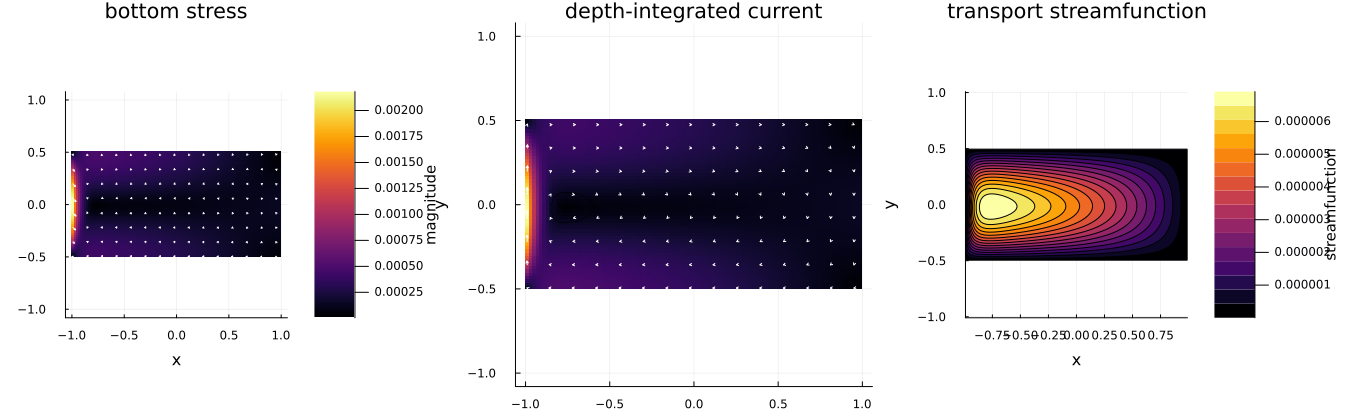

In [5]:
bottom_stress_figure = plot_bottom_stress(
    diagnostics;
    arrow_scale=0.30,
    output=joinpath(@__DIR__, "stommel_pg_bottom_stress.png"),
)
transport_figure = plot_depth_integrated_current(
    diagnostics;
    arrow_scale=0.30,
    output=joinpath(@__DIR__, "stommel_pg_transport.png"),
)
streamfunction_figure = plot_streamfunction(
    diagnostics;
    output=joinpath(@__DIR__, "stommel_pg_streamfunction.png"),
)
diagnostic_figure = plot_diagnostics(
    diagnostics;
    arrow_scale=0.30,
    output=joinpath(@__DIR__, "stommel_pg_diagnostics.png"),
)
display(diagnostic_figure)

## Depth-integrated momentum balance

The DIM panels show the signed terms in equations (24)--(25), with a shared color scale for each momentum component. For this wind-driven example the buoyancy forcing is zero, so $\chi=0$ and $p_b=p_s$.

┌ Info: DIM diagnostic calculation started
│   Nx = 101
│   Ny = 51
│   wet_points = 5151
└ @ PlanetaryGeostrophy /Users/twnh/Library/CloudStorage/OneDrive-JohnsHopkins/Documents/Articles/Manuscripts/In prep/Haine_etal/WorkingResearch/PlanetaryGeostrophyAnalyticalModel/PlanetaryGeostrophy/src/PlanetaryGeostrophy.jl:2606
┌ Info: Starting sampling depth-integrated momentum terms
└ @ PlanetaryGeostrophy /Users/twnh/Library/CloudStorage/OneDrive-JohnsHopkins/Documents/Articles/Manuscripts/In prep/Haine_etal/WorkingResearch/PlanetaryGeostrophyAnalyticalModel/PlanetaryGeostrophy/src/PlanetaryGeostrophy.jl:18
┌ Info: DIM diagnostic sampling progress
│   rows_completed = 1
│   rows_total = 51
│   percent = 2.0
└ @ PlanetaryGeostrophy /Users/twnh/Library/CloudStorage/OneDrive-JohnsHopkins/Documents/Articles/Manuscripts/In prep/Haine_etal/WorkingResearch/PlanetaryGeostrophyAnalyticalModel/PlanetaryGeostrophy/src/PlanetaryGeostrophy.jl:2633
┌ Info: DIM diagnostic sampling progress
│   rows_comple

(sampling = (seconds = 3.547157125, allocated_mib = 1901.9115295410156, gc_seconds = 0.096850708), total_seconds = 3.548820972442627, x_relative_l2_residual = 4.729149188852037e-5, y_relative_l2_residual = 4.3021365116701284e-5)

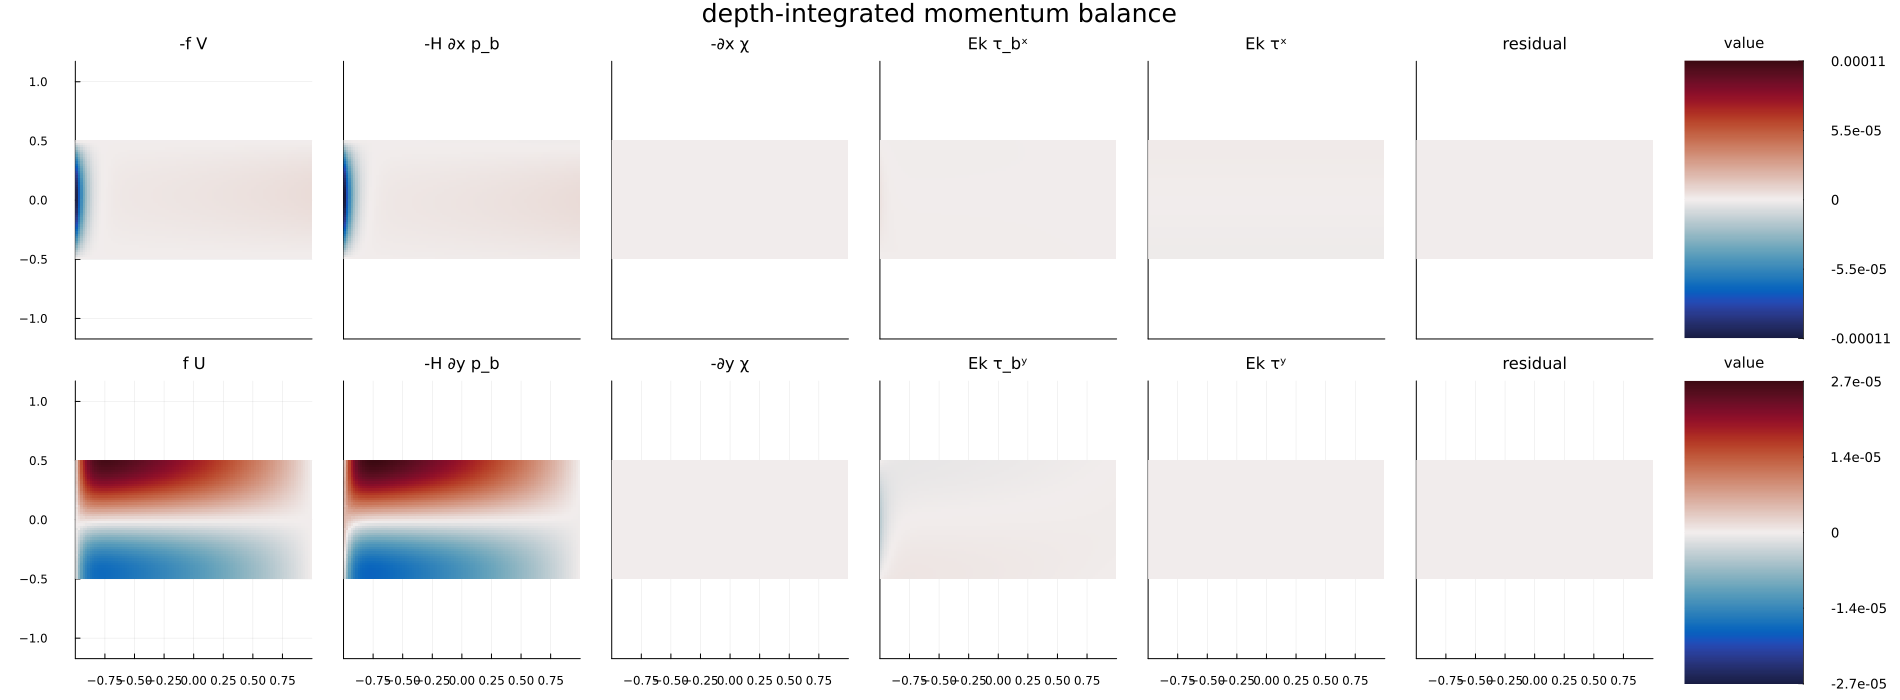

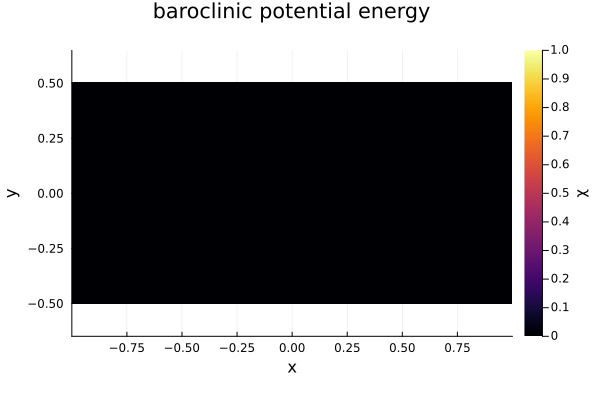

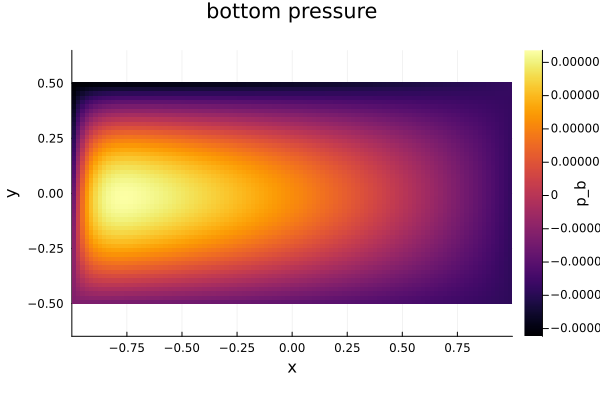

In [6]:
dim_diagnostics = compute_dim_diagnostics(solution, diagnostics)
display(performance_summary(dim_diagnostics))

dim_balance_figure = plot_dim_balance(
    dim_diagnostics;
    output=joinpath(@__DIR__, "stommel_pg_dim_balance.png"),
)
chi_figure = plot_baroclinic_potential_energy(
    dim_diagnostics;
    output=joinpath(@__DIR__, "stommel_pg_chi.png"),
)
bottom_pressure_figure = plot_bottom_pressure(
    dim_diagnostics;
    output=joinpath(@__DIR__, "stommel_pg_bottom_pressure.png"),
)

display(dim_balance_figure)
display(chi_figure)
display(bottom_pressure_figure)

## Depth-integrated vorticity balance

For this flat-bottom beta-plane problem, $w|_{z=-H}=0$, so equation (32) reduces to a balance between $\beta V$ and the curls of the surface and bottom stresses.

┌ Info: Starting cell-averaged budget integrals
└ @ PlanetaryGeostrophy /Users/twnh/Library/CloudStorage/OneDrive-JohnsHopkins/Documents/Articles/Manuscripts/In prep/Haine_etal/WorkingResearch/PlanetaryGeostrophyAnalyticalModel/PlanetaryGeostrophy/src/PlanetaryGeostrophy.jl:18
┌ Info: Completed cell-averaged budget integrals
│   seconds = 20.589
│   allocated_mib = 35185.97
│   gc_seconds = 1.541
└ @ PlanetaryGeostrophy /Users/twnh/Library/CloudStorage/OneDrive-JohnsHopkins/Documents/Articles/Manuscripts/In prep/Haine_etal/WorkingResearch/PlanetaryGeostrophyAnalyticalModel/PlanetaryGeostrophy/src/PlanetaryGeostrophy.jl:21
┌ Info: Vorticity diagnostic calculation completed
│   method = cell_average
│   seconds = 20.59
│   relative_l2_residual = 0.0237
└ @ PlanetaryGeostrophy /Users/twnh/Library/CloudStorage/OneDrive-JohnsHopkins/Documents/Articles/Manuscripts/In prep/Haine_etal/WorkingResearch/PlanetaryGeostrophyAnalyticalModel/PlanetaryGeostrophy/src/CellBudgets.jl:375
┌ Info: Plotting

(sampling = (seconds = 20.589208292, allocated_mib = 35185.97392272949, gc_seconds = 1.541293302), total_seconds = 20.589532136917114, relative_l2_residual = 0.023704188725708605)

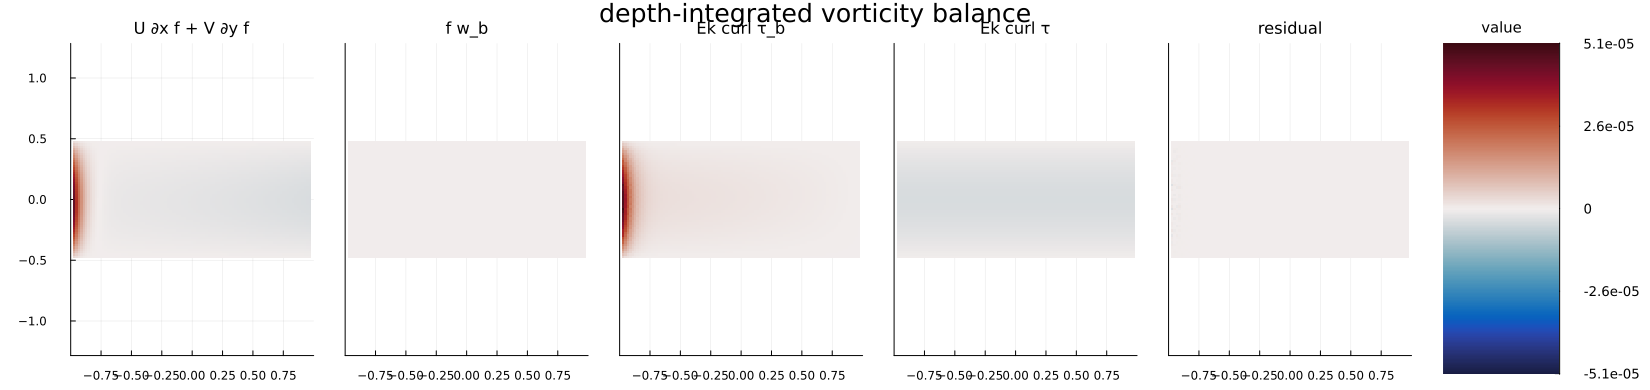

In [7]:
vorticity_diagnostics = compute_vorticity_diagnostics(solution, diagnostics)
display(performance_summary(vorticity_diagnostics))

vorticity_figure = plot_vorticity_balance(
    vorticity_diagnostics;
    output=joinpath(@__DIR__, "stommel_pg_vorticity_balance.png"),
)
display(vorticity_figure)

## Geostrophic-contour vorticity balance

For this flat-bottom problem, JEBAR vanishes and $f/H$ contours are latitude circles. Equation (34) therefore diagnoses the same wind- and bottom-stress closure as the depth-integrated vorticity balance, expressed as transport across geostrophic contours.

(sampling = (seconds = 20.589208292, allocated_mib = 35185.97392272949, gc_seconds = 1.541293302), total_seconds = 0.29253697395324707, relative_l2_residual = 0.023704188725708605)

┌ Info: GCVB diagnostic calculation completed
│   method = cell_average
│   seconds = 0.293
│   relative_l2_residual = 0.0237
└ @ PlanetaryGeostrophy /Users/twnh/Library/CloudStorage/OneDrive-JohnsHopkins/Documents/Articles/Manuscripts/In prep/Haine_etal/WorkingResearch/PlanetaryGeostrophyAnalyticalModel/PlanetaryGeostrophy/src/CellBudgets.jl:416
┌ Info: Plotting geostrophic-contour vorticity balance
│   output = /Users/twnh/Library/CloudStorage/OneDrive-JohnsHopkins/Documents/Articles/Manuscripts/In prep/Haine_etal/WorkingResearch/PlanetaryGeostrophyAnalyticalModel/AnalyticalModel/stommel_pg_geostrophic_contour_vorticity_balance.png
└ @ PlanetaryGeostrophy /Users/twnh/Library/CloudStorage/OneDrive-JohnsHopkins/Documents/Articles/Manuscripts/In prep/Haine_etal/WorkingResearch/PlanetaryGeostrophyAnalyticalModel/PlanetaryGeostrophy/src/PlanetaryGeostrophy.jl:4134
┌ Info: Starting rendering geostrophic-contour vorticity balance plot
└ @ PlanetaryGeostrophy /Users/twnh/Library/CloudStorage

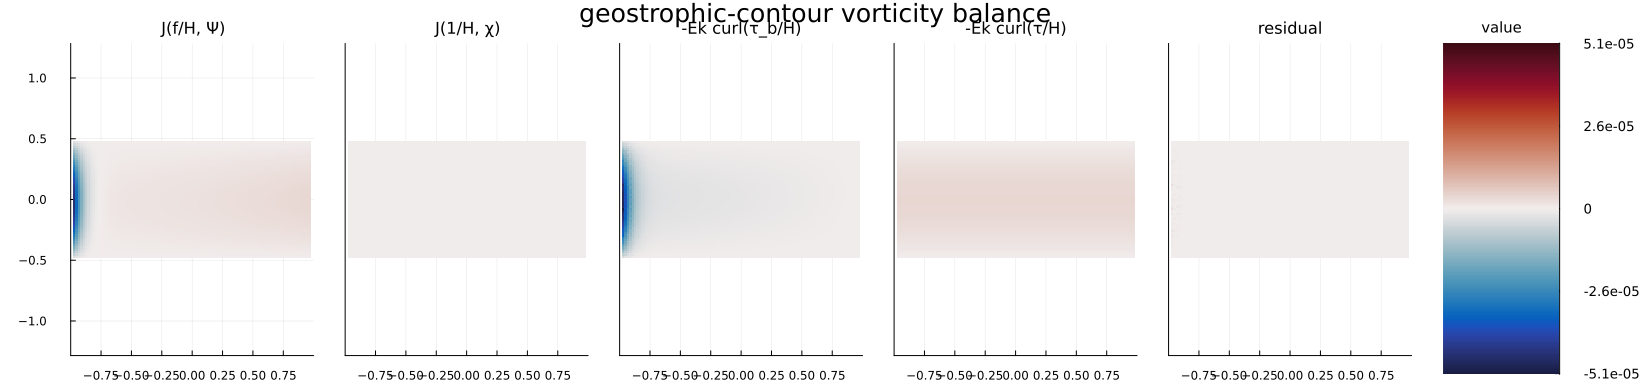

In [8]:
gcvb_diagnostics = compute_geostrophic_contour_vorticity_diagnostics(
    solution, diagnostics,
)
display(performance_summary(gcvb_diagnostics))

gcvb_figure = plot_geostrophic_contour_vorticity_balance(
    gcvb_diagnostics;
    output=joinpath(@__DIR__, "stommel_pg_geostrophic_contour_vorticity_balance.png"),
)
display(gcvb_figure)

## Transport-divergence vorticity balance

For this flat-bottom, unstratified problem, equation (37) diagnoses cancellation between the bottom-pressure torque associated with $H/f$ and the Coriolis-weighted surface and bottom stress curls; the baroclinic term vanishes.

(sampling = (seconds = 20.589208292, allocated_mib = 35185.97392272949, gc_seconds = 1.541293302), total_seconds = 4.696846008300781e-5, relative_l2_residual = 0.022969094520942698)

┌ Info: TDVB diagnostic calculation completed
│   method = cell_average
│   seconds = 0.0
│   relative_l2_residual = 0.02297
└ @ PlanetaryGeostrophy /Users/twnh/Library/CloudStorage/OneDrive-JohnsHopkins/Documents/Articles/Manuscripts/In prep/Haine_etal/WorkingResearch/PlanetaryGeostrophyAnalyticalModel/PlanetaryGeostrophy/src/CellBudgets.jl:457
┌ Info: Plotting transport-divergence vorticity balance
│   output = /Users/twnh/Library/CloudStorage/OneDrive-JohnsHopkins/Documents/Articles/Manuscripts/In prep/Haine_etal/WorkingResearch/PlanetaryGeostrophyAnalyticalModel/AnalyticalModel/stommel_pg_transport_divergence_vorticity_balance.png
└ @ PlanetaryGeostrophy /Users/twnh/Library/CloudStorage/OneDrive-JohnsHopkins/Documents/Articles/Manuscripts/In prep/Haine_etal/WorkingResearch/PlanetaryGeostrophyAnalyticalModel/PlanetaryGeostrophy/src/PlanetaryGeostrophy.jl:4193
┌ Info: Starting rendering transport-divergence vorticity balance plot
└ @ PlanetaryGeostrophy /Users/twnh/Library/CloudStora

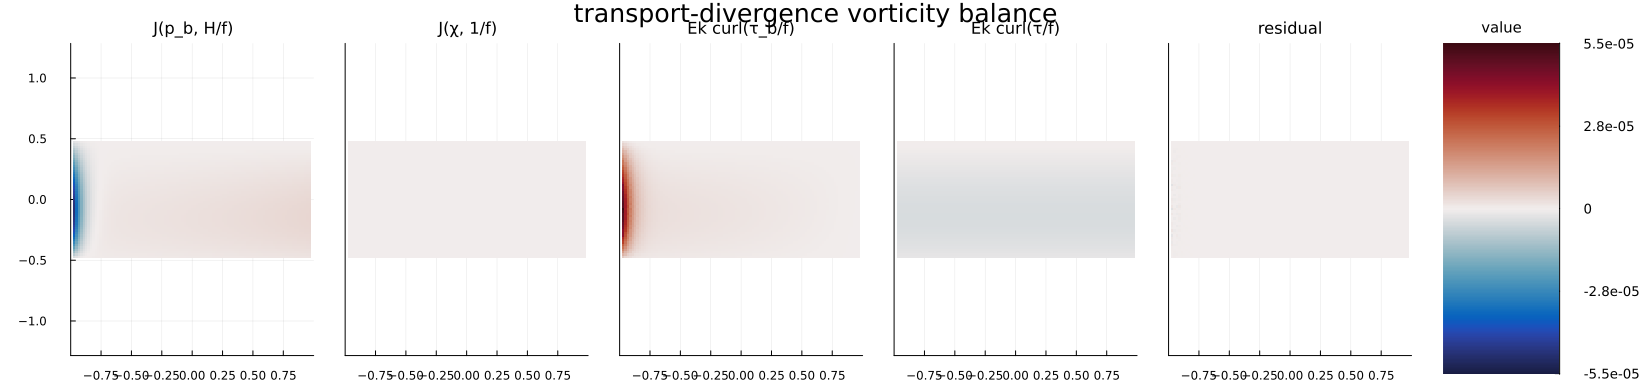

In [9]:
tdvb_diagnostics = compute_transport_divergence_vorticity_diagnostics(
    solution, diagnostics,
)
display(performance_summary(tdvb_diagnostics))

tdvb_figure = plot_transport_divergence_vorticity_balance(
    tdvb_diagnostics;
    output=joinpath(@__DIR__, "stommel_pg_transport_divergence_vorticity_balance.png"),
)
display(tdvb_figure)

## Surface-pressure equation coefficients

For the flat-bottom Stommel problem, equation (59) shows how the spatially varying Coriolis parameter sets the pressure-advection velocity and frictional diffusivity. The source is split into baroclinic and surface-stress contributions; the baroclinic contribution vanishes here because buoyancy forcing is zero.

┌ Info: Surface-pressure equation diagnostic calculation started
│   Nx = 101
│   Ny = 51
│   wet_points = 5151
└ @ PlanetaryGeostrophy /Users/twnh/Library/CloudStorage/OneDrive-JohnsHopkins/Documents/Articles/Manuscripts/In prep/Haine_etal/WorkingResearch/PlanetaryGeostrophyAnalyticalModel/PlanetaryGeostrophy/src/PlanetaryGeostrophy.jl:3238
┌ Info: Starting sampling surface-pressure equation coefficients
└ @ PlanetaryGeostrophy /Users/twnh/Library/CloudStorage/OneDrive-JohnsHopkins/Documents/Articles/Manuscripts/In prep/Haine_etal/WorkingResearch/PlanetaryGeostrophyAnalyticalModel/PlanetaryGeostrophy/src/PlanetaryGeostrophy.jl:18
┌ Info: Surface-pressure equation diagnostic sampling progress
│   rows_completed = 1
│   rows_total = 51
│   percent = 2.0
└ @ PlanetaryGeostrophy /Users/twnh/Library/CloudStorage/OneDrive-JohnsHopkins/Documents/Articles/Manuscripts/In prep/Haine_etal/WorkingResearch/PlanetaryGeostrophyAnalyticalModel/PlanetaryGeostrophy/src/PlanetaryGeostrophy.jl:3268
┌ Inf

(sampling = (seconds = 0.031947917, allocated_mib = 73.36344909667969, gc_seconds = 0.009138542), total_seconds = 0.0322420597076416, sampled_wet_points = 5151, wet_points = 4851, points_per_second = 151840.88527586948, relative_l2_residual = 0.09825321196195914)

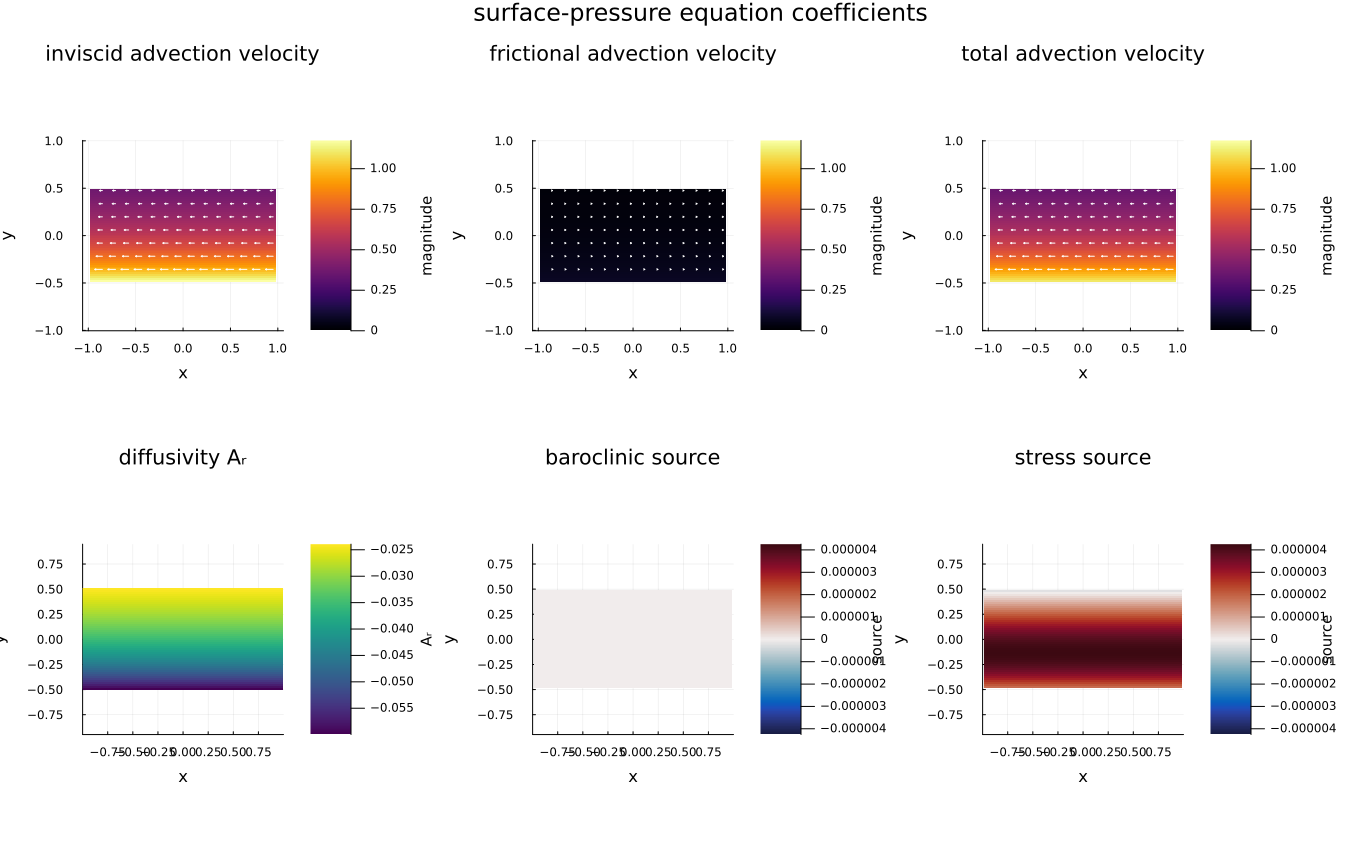

In [10]:
pressure_equation_diagnostics = compute_surface_pressure_equation_diagnostics(
    solution, diagnostics,
)
display(performance_summary(pressure_equation_diagnostics))

pressure_equation_figure = plot_surface_pressure_equation_diagnostics(
    pressure_equation_diagnostics;
    arrow_scale=0.70,
    output=joinpath(@__DIR__, "stommel_pg_surface_pressure_equation.png"),
)
display(pressure_equation_figure)

## Sverdrup-interior comparison

Away from the western boundary, $V_{Sv}=\mathrm{Ek}\,\operatorname{curl}(\tau)/\beta$. Integrating $\partial_x\Psi_{Sv}=V_{Sv}$ from the eastern boundary gives an interior streamfunction that does not satisfy the western no-normal-flow condition. The difference from the PG solution therefore highlights the frictional western boundary layer.

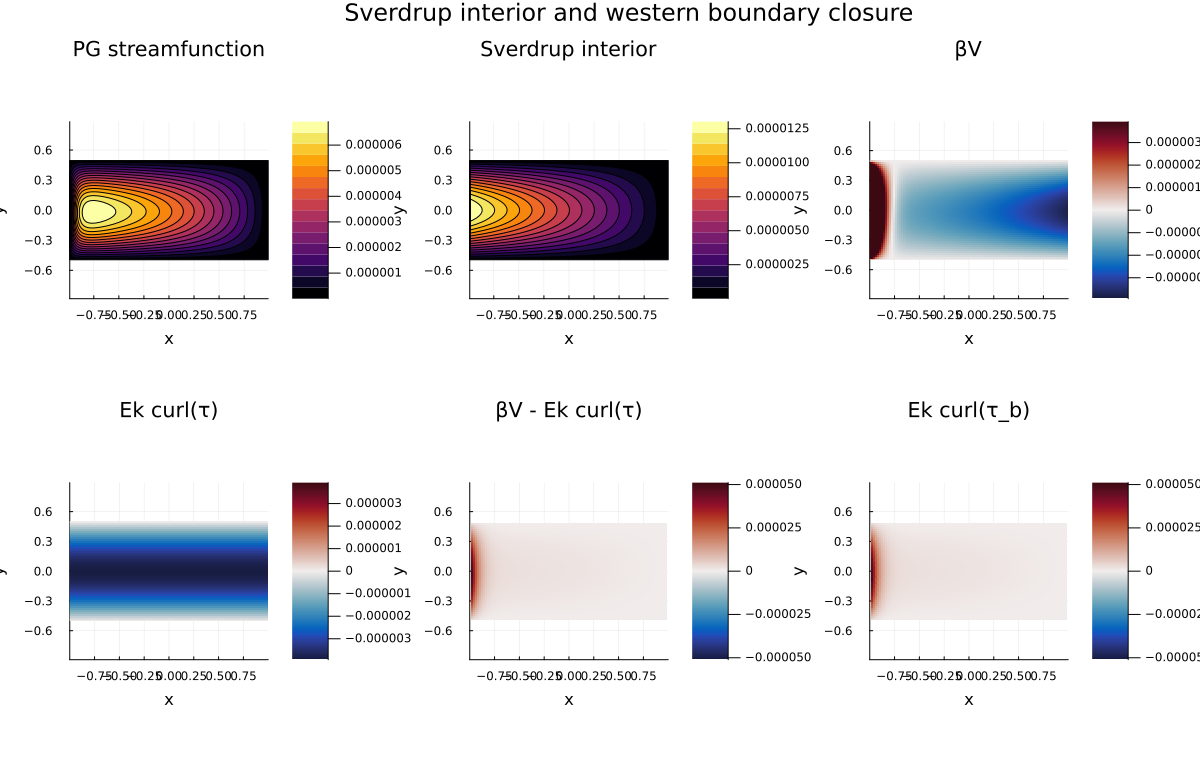

In [11]:
sverdrup_V = [Ek * wind_curl(xx, yy) / beta for xx in x, yy in y]
sverdrup_streamfunction = [
    Ek * (xx - Lx / 2) * wind_curl(xx, yy) / beta for xx in x, yy in y
]
transport_speed = hypot.(diagnostics.transport_U, diagnostics.transport_V)
planetary_vorticity = beta .* diagnostics.analytical_transport_V
surface_stress_curl = [Ek * wind_curl(xx, yy) for xx in x, yy in y]
sverdrup_departure = planetary_vorticity .- surface_stress_curl
sverdrup_departure[.!vorticity_diagnostics.wet] .= NaN
sverdrup_scale = maximum(abs, surface_stress_curl)
boundary_scale = maximum(abs, [
    sverdrup_departure[vorticity_diagnostics.wet];
    vorticity_diagnostics.bottom_stress_curl[vorticity_diagnostics.wet];
])

p1 = contourf(x, y, diagnostics.streamfunction';
    title="PG streamfunction", xlabel="x", ylabel="y", aspect_ratio=:equal)
p2 = contourf(x, y, sverdrup_streamfunction';
    title="Sverdrup interior", xlabel="x", ylabel="y", aspect_ratio=:equal)
p3 = heatmap(x, y, planetary_vorticity';
    title="βV", xlabel="x", ylabel="y", aspect_ratio=:equal,
    color=:balance, clims=(-sverdrup_scale, sverdrup_scale))
p4 = heatmap(x, y, surface_stress_curl';
    title="Ek curl(τ)", xlabel="x", ylabel="y", aspect_ratio=:equal,
    color=:balance, clims=(-sverdrup_scale, sverdrup_scale))
p5 = heatmap(x, y, sverdrup_departure';
    title="βV - Ek curl(τ)", xlabel="x", ylabel="y", aspect_ratio=:equal,
    color=:balance, clims=(-boundary_scale, boundary_scale))
p6 = heatmap(x, y, vorticity_diagnostics.bottom_stress_curl';
    title="Ek curl(τ_b)", xlabel="x", ylabel="y", aspect_ratio=:equal,
    color=:balance, clims=(-boundary_scale, boundary_scale))
comparison_figure = plot(p1, p2, p3, p4, p5, p6;
    layout=(2, 3), size=(1200, 760),
    plot_title="Sverdrup interior and western boundary closure")
savefig(comparison_figure, joinpath(@__DIR__, "stommel_pg_sverdrup_comparison.png"))
display(comparison_figure)

In [12]:
western = x .< -Lx / 4
eastern = x .> Lx / 4
western_peak = maximum(transport_speed[western, :])
eastern_peak = maximum(transport_speed[eastern, :])
western_intensification = western_peak / eastern_peak
interior = [xx > -0.4 && xx < 0.8 && abs(yy) < 0.4 for xx in x, yy in y]
sverdrup_relative_error = sqrt(
    sum(abs2, diagnostics.analytical_transport_V[interior] .- sverdrup_V[interior]) /
    sum(abs2, sverdrup_V[interior]),
)
sverdrup_amplitude_ratio = (
    sum(diagnostics.analytical_transport_V[interior] .* sverdrup_V[interior]) /
    sum(abs2, sverdrup_V[interior])
)
sverdrup_shape_correlation = (
    sum(diagnostics.analytical_transport_V[interior] .* sverdrup_V[interior]) /
    sqrt(
        sum(abs2, diagnostics.analytical_transport_V[interior]) *
        sum(abs2, sverdrup_V[interior]),
    )
)
display((;
    western_peak,
    eastern_peak,
    western_intensification,
    sverdrup_relative_error,
    sverdrup_amplitude_ratio,
    sverdrup_shape_correlation,
))

(western_peak = 0.00010618853558799994, eastern_peak = 9.112123261051021e-6, western_intensification = 11.653544683915067, sverdrup_relative_error = 0.3952053067066118, sverdrup_amplitude_ratio = 0.6263771346798106, sverdrup_shape_correlation = 0.9795019410770138)